First 5 rows:
   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa


C:\Users\lalit\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\lalit\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\lalit\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\lalit\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  

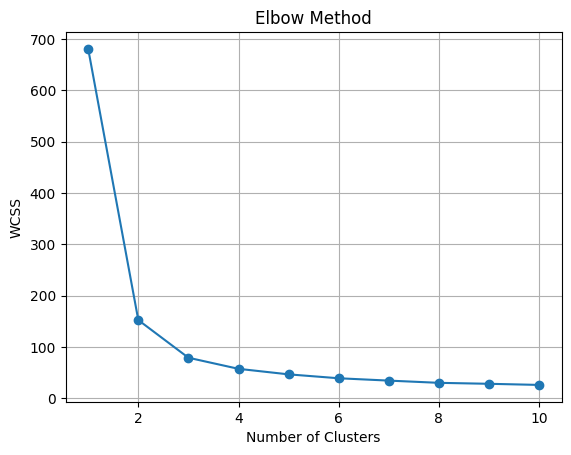


Cluster results:
   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm  Cluster
0            5.1           3.5            1.4           0.2        1
1            4.9           3.0            1.4           0.2        1
2            4.7           3.2            1.3           0.2        1
3            4.6           3.1            1.5           0.2        1
4            5.0           3.6            1.4           0.2        1


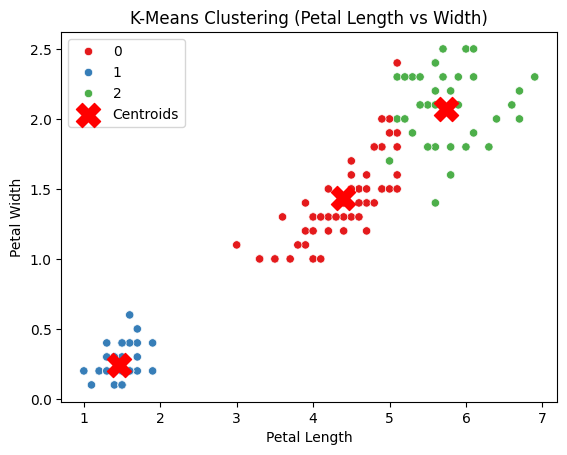


Accuracy of K-Means clustering: 89.33%

Confusion Matrix:
[[50  0  0]
 [ 0 48  2]
 [ 0 14 36]]


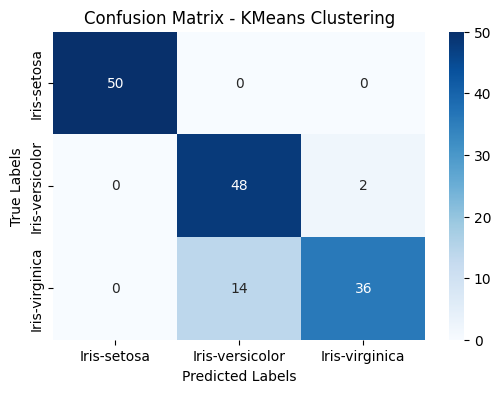

In [1]:

# Practical 4: K-Means Clustering on Iris Dataset

# Step 1: Import Required Libraries
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.preprocessing import LabelEncoder
from scipy.stats import mode

# Step 2: Load the Iris Dataset
data = pd.read_csv("Iris.csv")

# Step 3: Display First 5 Rows
print("First 5 rows:")
print(data.head())

# Step 4: Drop Unnecessary Columns
X = data.drop(['Id', 'Species'], axis=1)

# Step 5: Elbow Method to Find Optimal Clusters
wcss = []

for i in range(1, 11):
    kmeans = KMeans(
        n_clusters=i,
        init='k-means++',
        random_state=42,
        n_init=10
    )
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

# Step 6: Plot Elbow Graph
plt.plot(range(1, 11), wcss, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.grid(True)
plt.show()

# Step 7: Apply K-Means with 3 Clusters
kmeans = KMeans(
    n_clusters=3,
    init='k-means++',
    random_state=42,
    n_init=10
)

y_kmeans = kmeans.fit_predict(X)

# Step 8: Add Cluster Labels to Dataset
data['Cluster'] = y_kmeans

print("\nCluster results:")
print(data[['SepalLengthCm', 'SepalWidthCm',
            'PetalLengthCm', 'PetalWidthCm',
            'Cluster']].head())

# Step 9: Visualize the Clusters
sns.scatterplot(
    x='PetalLengthCm',
    y='PetalWidthCm',
    hue='Cluster',
    data=data,
    palette='Set1'
)

# Plot cluster centroids
plt.scatter(
    kmeans.cluster_centers_[:, 2],
    kmeans.cluster_centers_[:, 3],
    s=300,
    marker='X',
    c='red',
    label='Centroids'
)

plt.xlabel('Petal Length')
plt.ylabel('Petal Width')
plt.title('K-Means Clustering (Petal Length vs Width)')
plt.legend()
plt.show()

# Step 10: Define Actual Labels
y_true = data['Species']

# Step 11: Encode Species Labels
le = LabelEncoder()
y_encoded = le.fit_transform(y_true)

# Step 12: Map Clusters to Actual Labels
labels_mapped = np.zeros_like(y_kmeans)

for cluster in range(3):
    mask = (y_kmeans == cluster)

    labels_mapped[mask] = mode(
        y_encoded[mask],
        keepdims=True
    ).mode[0]

# Step 13: Calculate Accuracy
accuracy = accuracy_score(y_encoded, labels_mapped)

print("\nAccuracy of K-Means clustering:",
      f"{accuracy * 100:.2f}%")

# Step 14: Calculate Confusion Matrix
cm = confusion_matrix(
    y_encoded,
    labels_mapped,
    labels=np.arange(len(le.classes_))
)

print("\nConfusion Matrix:")
print(cm)

# Step 15: Plot Confusion Matrix Heatmap
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=le.classes_,
    yticklabels=le.classes_
)

plt.title("Confusion Matrix - KMeans Clustering")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()
